# Detecção de fraude em transações com classe rara

**Objetivo:** construir um modelo que identifique transações fraudulentas quando a fraude é uma fração mínima da base, escolhendo o ponto de corte pelo **custo do erro**, e não pela acurácia.

**Dados:** base **sintética**, gerada em `src/gerar_dados.py`, que simula transações de cartão. Nenhum dado real é usado.

**Roteiro**
1. Entender a base e o desbalanceamento
2. Separar treino e teste respeitando o tempo (*out of time*)
3. Comparar modelos: baseline, regressão logística com `class_weight`, SMOTE, Random Forest e Gradient Boosting
4. Avaliar com métricas adequadas a classe rara: recall, precision, PR-AUC, ROC-AUC, KS e Gini
5. Escolher o threshold pelo custo de falso negativo x falso positivo
6. Interpretar o modelo

In [1]:
import sys; sys.path.insert(0, 'src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gerar_dados import gerar_transacoes
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, roc_curve)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
plt.rcParams['figure.figsize'] = (8, 4)
SEED = 42

## 1. A base e o desbalanceamento

In [2]:
df = gerar_transacoes()
print(df.shape)
print(f"Taxa de fraude: {df['fraude'].mean():.2%}")
df.head()

(60000, 10)
Taxa de fraude: 0.98%


,data,hora,valor,distancia_casa_km,dispositivo_novo,transacoes_ultima_hora,pais_diferente,canal,valor_vs_media_cliente,fraude
0,2025-01-01,19,39.80,5.8,0,0,0,app,1.21,0
1,2025-01-01,9,122.07,13.1,0,2,0,presencial,1.18,0
2,2025-01-01,12,126.17,8.4,0,0,0,presencial,1.90,0
3,2025-01-01,0,88.24,5.0,0,0,0,online,1.11,0
4,2025-01-01,13,45.82,2.2,0,0,0,online,0.42,0


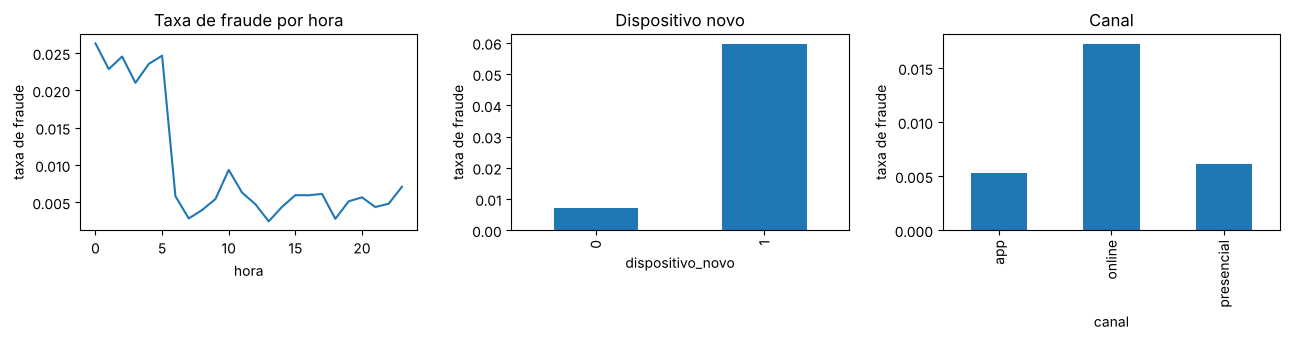

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby('hora')['fraude'].mean().plot(ax=ax[0], title='Taxa de fraude por hora')
df.groupby('dispositivo_novo')['fraude'].mean().plot.bar(ax=ax[1], title='Dispositivo novo')
df.groupby('canal')['fraude'].mean().plot.bar(ax=ax[2], title='Canal')
for a in ax: a.set_ylabel('taxa de fraude')
plt.tight_layout(); plt.show()

**Leitura:** com menos de 1% de fraude, um modelo que diz sempre *não é fraude* acertaria mais de 99% das vezes e não pegaria nenhuma fraude. Por isso a acurácia não serve aqui.

## 2. Treino e teste no tempo (*out of time*)
Treino nos primeiros 4 meses e teste nos 2 últimos. Isso simula o uso real: o modelo decide sobre transações que vêm depois do que ele viu.

In [4]:
corte = df['data'].min() + pd.Timedelta(days=120)
treino, teste = df[df['data'] < corte], df[df['data'] >= corte]
num = ['hora', 'valor', 'distancia_casa_km', 'dispositivo_novo', 'transacoes_ultima_hora',
       'pais_diferente', 'valor_vs_media_cliente']
cat = ['canal']
X_tr, y_tr = treino[num + cat], treino['fraude']
X_te, y_te = teste[num + cat], teste['fraude']
print(f"Treino: {len(treino):,} linhas | fraude {y_tr.mean():.2%}")
print(f"Teste:  {len(teste):,} linhas | fraude {y_te.mean():.2%}")

Treino: 40,012 linhas | fraude 0.98%
Teste:  19,988 linhas | fraude 0.98%


## 3. Comparação de modelos

In [5]:
prep = ColumnTransformer([('num', StandardScaler(), num),
                          ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)

modelos = {
    'Logística (sem balancear)': Pipeline([('prep', prep), ('m', LogisticRegression(max_iter=1000))]),
    'Logística + class_weight': Pipeline([('prep', prep), ('m', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
    'Logística + SMOTE': ImbPipeline([('prep', prep), ('smote', SMOTE(random_state=SEED)), ('m', LogisticRegression(max_iter=1000))]),
    'Random Forest + class_weight': Pipeline([('prep', prep), ('m', RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
    'Gradient Boosting': Pipeline([('prep', prep), ('m', HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED))]),
}

linhas, probs = [], {}
for nome, pipe in modelos.items():
    pipe.fit(X_tr, y_tr)
    p = pipe.predict_proba(X_te)[:, 1]
    probs[nome] = p
    pred = (p >= 0.5).astype(int)
    auc = roc_auc_score(y_te, p)
    linhas.append({'modelo': nome, 'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks(y_te, p),
                   'PR-AUC': average_precision_score(y_te, p),
                   'recall@0.5': recall_score(y_te, pred), 'precision@0.5': precision_score(y_te, pred, zero_division=0)})
res = pd.DataFrame(linhas).set_index('modelo').round(3)
res

,ROC-AUC,Gini,KS,PR-AUC,recall@0.5,precision@0.5
modelo,,,,,,
Logística (sem balancear),0.888,0.776,0.665,0.250,0.102,0.606
Logística + class_weight,0.901,0.803,0.676,0.212,0.806,0.054
Logística + SMOTE,0.900,0.799,0.679,0.213,0.801,0.054
Random Forest + class_weight,0.905,0.810,0.679,0.299,0.592,0.155
Gradient Boosting,0.904,0.809,0.669,0.310,0.168,0.589


**Leitura:**
- O modelo **sem balanceamento** tem AUC parecida, mas com threshold 0,5 quase não aponta fraude: o recall fica muito baixo.
- `class_weight` e SMOTE sobem muito o recall, à custa de precision. A escolha certa do threshold vem na próxima etapa.
- **PR-AUC** é a métrica mais honesta com classe rara, porque não é inflada pela grande quantidade de negativos.

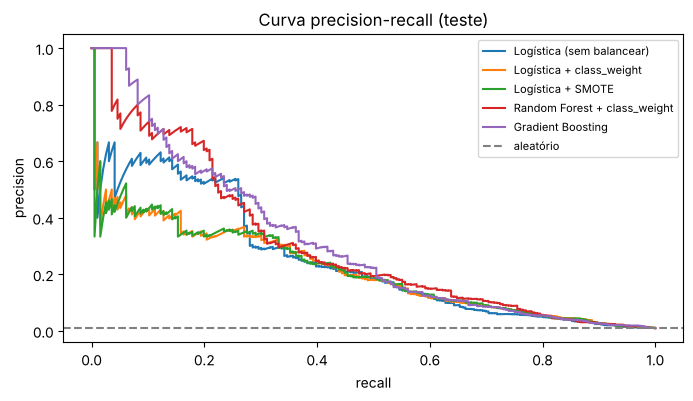

In [6]:
fig, ax = plt.subplots()
for nome, p in probs.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, label=nome)
ax.axhline(y_te.mean(), ls='--', c='gray', label='aleatório')
ax.set_xlabel('recall'); ax.set_ylabel('precision'); ax.set_title('Curva precision-recall (teste)')
ax.legend(fontsize=8); plt.show()

## 4. Threshold pelo custo do erro

Premissas de exemplo, que no mundo real seriam definidas com o negócio:
- **Falso negativo** (fraude que passa): custo igual ao valor da transação.
- **Falso positivo** (bloquear cliente bom): custo fixo de R$ 15, que representa atrito, atendimento e risco de perder o cliente.

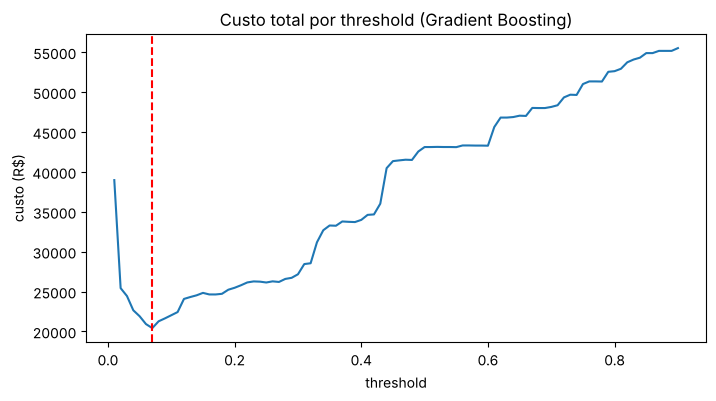

Modelo escolhido: Gradient Boosting
Threshold ótimo: 0.07
Recall: 49.0% | Precision: 22.5%
Custo sem modelo (toda fraude passa): R$ 56,317
Custo com modelo: R$ 20,423  ->  redução de 63.7%
Clientes bons bloqueados: 331 de 19792 (1.67%)


In [7]:
melhor = res['PR-AUC'].idxmax()
p = probs[melhor]
CUSTO_FP = 15
valores = teste['valor'].values

def custo_total(th):
    pred = p >= th
    fn = (~pred) & (y_te.values == 1)
    fp = pred & (y_te.values == 0)
    return valores[fn].sum() + CUSTO_FP * fp.sum()

ths = np.linspace(0.01, 0.9, 90)
custos = [custo_total(t) for t in ths]
th_otimo = ths[int(np.argmin(custos))]
sem_modelo = valores[y_te.values == 1].sum()

plt.plot(ths, custos); plt.axvline(th_otimo, ls='--', c='red')
plt.title(f'Custo total por threshold ({melhor})'); plt.xlabel('threshold'); plt.ylabel('custo (R$)'); plt.show()

pred = p >= th_otimo
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f"Modelo escolhido: {melhor}")
print(f"Threshold ótimo: {th_otimo:.2f}")
print(f"Recall: {tp/(tp+fn):.1%} | Precision: {tp/(tp+fp):.1%}")
print(f"Custo sem modelo (toda fraude passa): R$ {sem_modelo:,.0f}")
print(f"Custo com modelo: R$ {min(custos):,.0f}  ->  redução de {1 - min(custos)/sem_modelo:.1%}")
print(f"Clientes bons bloqueados: {fp} de {tn+fp} ({fp/(tn+fp):.2%})")

**Leitura:** o threshold ótimo fica bem abaixo de 0,5. Como deixar passar uma fraude custa mais que revisar uma transação boa, compensa aceitar mais falsos positivos para pegar mais fraudes. Mudando o custo do falso positivo, o ponto ótimo muda, e essa é uma decisão de negócio.

## 5. O que o modelo aprendeu

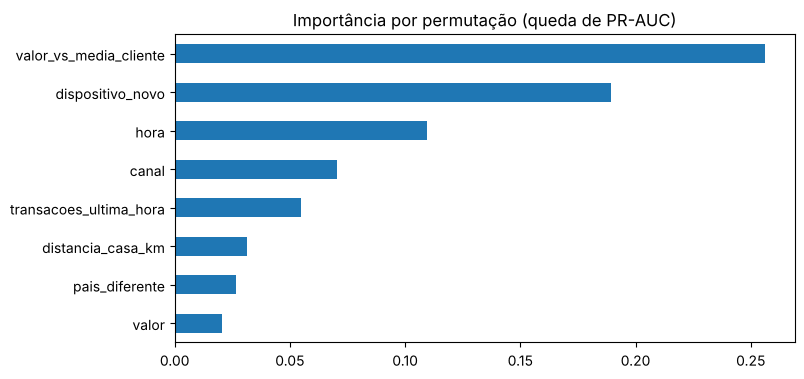

In [8]:
imp = permutation_importance(modelos[melhor], X_te, y_te, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)
pd.Series(imp.importances_mean, index=num + cat).sort_values().plot.barh(title='Importância por permutação (queda de PR-AUC)')
plt.show()

## Conclusões

- Em classe rara, **acurácia engana**. Recall, precision e PR-AUC mostram o desempenho real.
- O **threshold** deve sair do custo do erro, junto com o negócio, e não do padrão 0,5.
- A validação **out of time** simula o uso real e evita resultados otimistas.

**Limitações e próximos passos**
- Os dados são sintéticos. Em dados reais, a fraude muda de padrão com o tempo (*concept drift*), então é preciso monitorar o modelo e retreinar.
- Rótulos de fraude chegam com atraso, como em contestações, o que afeta a janela de treino.
- Próximos passos: variáveis de histórico por cliente com janelas de tempo, calibração das probabilidades e monitoramento de drift.